In [2]:
# just for this machine
import os
os.environ["CUDA_VISIBLE_DEVICES"] = "2"


In [3]:
from pathlib import Path


In [4]:
import numpy as np
import matplotlib.pyplot as plt
#import torch
import spikeinterface.full as si
import scipy.signal
from tqdm.auto import tqdm, trange
import argparse


In [5]:
# parser = argparse.ArgumentParser()
# parser.add_argument('--animal_tag', type=str, required=True)
# parser.add_argument('--exp_tag', type=str, required=True)

# args = parser.parse_args()
# animal_tag = args.animal_tag
# exp_tag = args.exp_tag

animal_tag = 'GLC6811'
exp_tag = '_g2'
exp_num = f'{animal_tag}_{exp_tag}'
base_folder = f"/nexus/posix0/MBR-neuralsystems/ephys/{animal_tag}/{exp_num}/snippet"
rec_dir = os.path.join(base_folder, f'raw_0_900s')
#results_folder = "/u/gongt/GLC6962_l_g1"
results_folder_check = base_folder
results_folder_data = base_folder
Path(results_folder_data).mkdir(parents=True, exist_ok=True)


In [6]:
si.set_global_job_kwargs(n_jobs=4)


In [7]:
if 'imec0' in rec_dir:
    for meta_filename in Path(rec_dir).glob("*ap.meta"):
        print(meta_filename)

    word = 'imSampRate'
    with open(meta_filename, 'r') as meta_info:
        # read all lines in a list
        lines = meta_info.readlines()
        for line in lines:
            # check if string present on a current line
            if line.find(word) != -1:
                index = lines.index(line)

    line = lines[index]
    fs = line[11:]
    fs = float(fs)
    print(fs)


 ## Preprocessing

In [8]:
def load_rec(rec_dir):
    if 'imec0' in rec_dir:
        rec = si.read_spikeglx(rec_dir, stream_name='imec0.ap', load_sync_channel=False)
    else:
        rec = si.load(rec_dir)
    return rec


In [9]:
# this is setup for visualization
rec = load_rec(rec_dir)
rec.get_probe().to_dataframe()
print(rec)

n_seconds = rec.get_duration()
n_mins = n_seconds / 60
chlen = 512
t_start = rec.get_start_time()
min_start = int(np.ceil(t_start / 60))


BinaryFolderRecording: 384 channels - 30000.138084 Hz - 1 segments - 27,000,124 samples 
                       900.00s (15.00 minutes) - int16 dtype - 19.31 GiB


In [10]:
save_folder = os.path.join(results_folder_check, "raw_neural_data")

if not os.path.exists(save_folder) or len(os.listdir(save_folder)) == 0:
    os.makedirs(save_folder, exist_ok=True)
    print(f"Created folder {save_folder} for saving images")
    imkw = dict(aspect='auto', interpolation='none')
    for min_start in range(min_start, min_start + int(n_mins), 5):
        sample_start = rec.time_to_sample_index(min_start * 60)
        print(sample_start)
        chunk = rec.get_traces(0, sample_start, sample_start + chlen)

        fig, ax = plt.subplots(figsize=(4, 3))
        im = ax.imshow(chunk.T, **imkw)
        plt.colorbar(im, ax=ax, shrink=0.5)

        filename = os.path.join(save_folder, f"{min_start:04d}min.png")
        plt.savefig(filename, bbox_inches = 'tight')
        plt.show()
        plt.close(fig)
    print("all plots successfully saved")
else: 
    print(f"Folder {save_folder} already exists and is not empty. Skip saving images.")


Folder /nexus/posix0/MBR-neuralsystems/ephys/GLC6811/GLC6811__g2/snippet/raw_neural_data already exists and is not empty. Skip saving images.


In [11]:
# preprocess
rec0 = load_rec(rec_dir)  # to avoid stacking the ppx chain accidentally.
rec = si.highpass_filter(rec0, dtype="float32")
bc, labels = si.detect_bad_channels(rec, seed=0)
print(f"{bc=}")


bc=array(['imec0.ap#AP15', 'imec0.ap#AP26', 'imec0.ap#AP72',
       'imec0.ap#AP149', 'imec0.ap#AP157', 'imec0.ap#AP191',
       'imec0.ap#AP245'], dtype='<U14')


In [12]:
rec

HighpassFilterRecording: 384 channels - 30000.138084 Hz - 1 segments - 27,000,124 samples 
                         900.00s (15.00 minutes) - float32 dtype - 38.62 GiB

In [13]:
rec = rec.remove_channels(bc)


In [14]:
chunks = si.get_random_data_chunks(rec,  num_chunks_per_segment=100, seed=0)


In [15]:
std = chunks.std(0)


Channel std plot /nexus/posix0/MBR-neuralsystems/ephys/GLC6811/GLC6811__g2/snippet/raw_channel_std.png already exists. Skip saving.


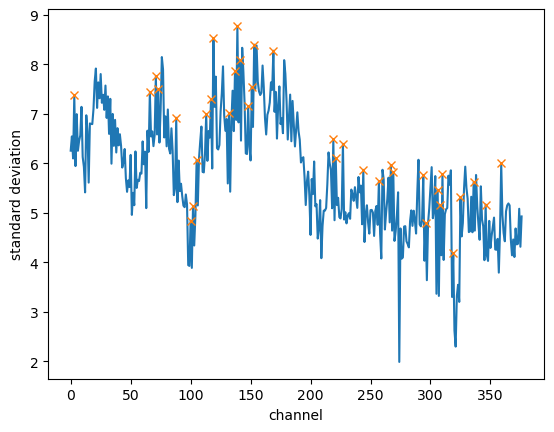

In [16]:
peaks, _ = scipy.signal.find_peaks(std, threshold=0.75)
plt.plot(std)
plt.plot(peaks, std[peaks], "x")
plt.xlabel('channel')
plt.ylabel('standard deviation')

save_path = os.path.join(results_folder_check, "raw_channel_std.png")
if not os.path.exists(save_path):
    plt.savefig(save_path, bbox_inches = 'tight')
    print(f"Saved channel std plot to {save_path}")
else: 
    print(f"Channel std plot {save_path} already exists. Skip saving.")

plt.show()
plt.close()


In [17]:
rec

ChannelSliceRecording: 377 channels - 30000.138084 Hz - 1 segments - 27,000,124 samples 
                       900.00s (15.00 minutes) - float32 dtype - 37.92 GiB

In [18]:
rec = rec.remove_channels(rec.channel_ids[peaks])
rec = si.common_reference(rec)
rec = si.zscore(rec,mode='median+mad')


In [19]:
rec

ZScoreRecording: 341 channels - 30000.138084 Hz - 1 segments - 27,000,124 samples 
                 900.00s (15.00 minutes) - float32 dtype - 34.30 GiB

 ## Extract TTLs

In [36]:
### Extract TTLs ### 
raw_rec = si.read_spikeglx(base_folder, stream_name='nidq', load_sync_channel=False)
raw_rec


FileNotFoundError: No appropriate combination of .meta and .bin files were detected in /nexus/posix0/MBR-neuralsystems/ephys/GLC6811/GLC6811__g2/snippet

In [ ]:
ttlName = ['sync','stim','side','overview','hi-res']
# input_name = input("Enter a name: ")
input_name = "overview"
chanInterest = ttlName.index(input_name)
chanInterest


In [ ]:
ttl_sig = raw_rec.get_traces()[:,chanInterest]
norm_sig = (ttl_sig - np.min(ttl_sig)) / (np.max(ttl_sig) - np.min(ttl_sig))
#median_signal = np.median(ttl_sig[ttl_sig > 0])
threshold = 0.5
thresh_signal = (norm_sig >= threshold).astype(int)
diff_sig = np.diff(thresh_signal)

indOn = np.where(diff_sig > 0.6)[0]
indOff = np.where(diff_sig < -0.6)[0]

ttl_on = indOn/fs
ttl_off = indOff/fs

len(ttl_on)


In [ ]:
filename = f"ttl_{input_name}_on2.txt"
save_filename = os.path.join(results_folder_check, filename)
with open(save_filename, "w") as f:
    f.write(",".join(map(str, ttl_on)))


 ## FIND EINK ARTIFACTS

In [39]:
################ BY SQR DEVIATION ###################
#### if triggers already known ## 
outlier_file = os.path.join(results_folder_check, "outliers_list_sqr_overview.txt")
if os.path.exists(outlier_file):
    print(f"Reading existing outlier list from {outlier_file}...")
    outliers_list = np.loadtxt(outlier_file, delimiter=',')
else: 
    print("Outlier list not found. Finding eInk artifacts...")
    rec1 = load_rec(rec_dir)
    save_folder = Path(os.path.join(results_folder_check, "artifact_plots_sqd", "detection"))
    save_folder.mkdir(parents=True, exist_ok=True)

    window_size_sec = 60
    std_threshold = 1000
    overlap_sec = 1 #when scanning the entire trace, the next chunk has 1s overlap with the previous chunk ==> aoivd an artifact being split into 2 chunks 
    total_samples = rec1.get_num_samples(segment_index=0)

    fs = rec1.get_sampling_frequency()
    window_size = int(window_size_sec * fs)-1
    overlap_size = int(overlap_sec * fs)
    step_size = window_size - overlap_size

    print(f"Total samples: {total_samples}, analyzing in {window_size_sec}s windows")

    outliers_list = []

    for start_sample in tqdm(range(0, total_samples, step_size), desc="Scanning dataset by minute"):
        end_sample = min(start_sample + window_size, total_samples)
        print(f"Processing samples {start_sample} to {end_sample}")
        trace = rec1.get_traces(0, start_sample, end_sample)
        trace_mean = np.mean(trace, axis=1)    
        mean_val = np.mean(trace_mean)
        std_val = np.std(trace_mean)
        time = np.arange(len(trace_mean)) + start_sample
        print(len(time))

        p_low, p_high = np.percentile(trace_mean, [20, 80])
        mask = (trace_mean >= p_low) & (trace_mean <= p_high)
        mean_robust, std_robust = np.mean(trace_mean[mask]), np.std(trace_mean[mask])
        sq_dev = (trace_mean - mean_robust) ** 2
        print(len(sq_dev))
        sq_dev_robust = sq_dev[mask]
        thresh_sq = np.mean(sq_dev_robust) + std_threshold * np.std(sq_dev_robust)

        fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(15, 8))
        ax1.plot(time, trace_mean, 'k-', alpha=0.8)
        ax1.set_title('Original Signal')
        ax1.set_ylabel('Amplitude')
        ax1.grid(True, alpha=0.3)

        ax2.plot(time, sq_dev, 'k-', alpha=0.8)
        ax2.axhline(thresh_sq, color='red', ls='--')
        ax2.set_title('Squared Deviation from Mean')
        ax2.set_ylabel('Squared Deviation')
        ax2.set_xlabel('Time (samples)')
        ax2.grid(True, alpha=0.3)
        
        outliers_sq_local = sq_dev > thresh_sq  # Local indices for plotting
        if np.any(outliers_sq_local): 
            outlier_indices_local = np.where(outliers_sq_local)[0]

            keep_mask = np.zeros_like(outlier_indices_local, dtype=bool)
            for i, idx in enumerate(outlier_indices_local):
                has_prev_neighbor = (i > 0) and (outlier_indices_local[i-1] == idx - 1)
                has_next_neighbor = (i < len(outlier_indices_local) - 1) and (outlier_indices_local[i+1] == idx + 1)
                if has_prev_neighbor or has_next_neighbor:
                    keep_mask[i] = True
            filtered_indices = outlier_indices_local[keep_mask]

            outlier_indices_global = filtered_indices + start_sample
            print(outlier_indices_global)
            outliers_list.extend(outlier_indices_global.tolist())

            for idx in filtered_indices:
                ax1.axvline(x=idx + start_sample, color='salmon', alpha=0.3, zorder = 1)
                ax2.axvline(x=idx + start_sample, color='salmon', alpha=0.3, zorder = 1)

        plt.tight_layout()
        
        save_path = save_folder / f"artifact_{start_sample}_{end_sample}.png"
        plt.savefig(save_path)
        plt.close(fig)

    print("Artifact detection complete!")

    outliers_list = np.array(outliers_list) / fs 
    print(outliers_list)

    input_name = "overview"
    def save_array(arr, label):
        filename = f"{label}_{input_name}.txt"
        save_path = os.path.join(results_folder_check, filename)
        with open(save_path, "w") as f:
            f.write(",".join(map(str, arr)))

    save_array(outliers_list, "outliers_list_sqr")


Outlier list not found. Finding eInk artifacts...
Total samples: 27000124, analyzing in 60s windows


Scanning dataset by minute:   0%|          | 0/16 [00:00<?, ?it/s]

Processing samples 0 to 1800007
1800007
1800007
Processing samples 1770007 to 3570014
1800007
1800007
Processing samples 3540014 to 5340021
1800007
1800007
Processing samples 5310021 to 7110028
1800007
1800007
Processing samples 7080028 to 8880035
1800007
1800007
Processing samples 8850035 to 10650042
1800007
1800007
Processing samples 10620042 to 12420049
1800007
1800007
Processing samples 12390049 to 14190056
1800007
1800007
Processing samples 14160056 to 15960063
1800007
1800007
Processing samples 15930063 to 17730070
1800007
1800007
Processing samples 17700070 to 19500077
1800007
1800007
Processing samples 19470077 to 21270084
1800007
1800007
Processing samples 21240084 to 23040091
1800007
1800007
Processing samples 23010091 to 24810098
1800007
1800007
Processing samples 24780098 to 26580105
1800007
1800007
Processing samples 26550105 to 27000124
450019
450019
Artifact detection complete!
[]


In [42]:
#print(eInkOff - eInkOn)
list_triggers = outliers_list
print(list_triggers)
list_triggers_samp = list_triggers*fs
print(len(list_triggers))

ms_before = 150
ms_after = 150
rec_clean = si.remove_artifacts(recording=rec, list_triggers=list_triggers_samp, mode='zeros',ms_before=ms_before,ms_after = ms_after)



[]
0


IndexError: index 0 is out of bounds for axis 0 with size 0

In [41]:
####### SWEEP ACROSS THE WHOLE DATASET - CHECK IF ALL ARTIFACTS ARE REMOVED ###########
rec1 = load_rec(rec_dir)

save_folder = Path(os.path.join(results_folder_check, "artifact_plots_sqd", "confirmation"))
save_folder.mkdir(parents=True, exist_ok=True)

window_size_sec = 20
threshold_std = 1.5
percent_outliers_threshold = 11
overlap_sec = 1 #when scanning the entire trace, the next chunk has 1s overlap with the previous chunk ==> aoivd an artifact being split into 2 chunks 
total_samples = rec1.get_num_samples(segment_index=0)

window_size = int(window_size_sec * fs)-1
overlap_size = int(overlap_sec * fs)
step_size = window_size - overlap_size

print(f"Total samples: {total_samples}, analyzing in {window_size_sec}s windows")

close_artifact_segments = []  # store sample ranges where space_to_prev <400 for 5 consecutive times

rec_clean_astype = rec_clean.astype('float16')

remaining_outliers = []
for start_sample in tqdm(range(0, total_samples, step_size), desc="Scanning dataset by minute"):
    end_sample = min(start_sample + window_size, total_samples)
    trace = rec1.get_traces(0, start_sample, end_sample)
    trace_mean = np.mean(trace, axis=1)
    mean_val = np.mean(trace_mean)
    std_val = np.std(trace_mean)
    upper_threshold = mean_val + threshold_std * std_val
    lower_threshold = mean_val - threshold_std * std_val
    outlier_indices = np.where((trace_mean > upper_threshold) | (trace_mean < lower_threshold))[0]
    percent_outliers = (len(outlier_indices) / len(trace_mean)) * 100
    print(f"Chunk {start_sample}–{end_sample}: {percent_outliers:.2f}% of samples exceed threshold")

    if percent_outliers < percent_outliers_threshold: # this filters out chunks where std is small with no huge outliers ==> a lot of samples are above threshold  
        clean_trace = rec_clean_astype.get_traces(0, start_sample, end_sample)
        clean_trace_mean = np.mean(clean_trace, axis=1)
        clean_mean_val = np.mean(clean_trace_mean)
        clean_std_val = np.std(clean_trace_mean)
        clean_upper_threshold = clean_mean_val + threshold_std * clean_std_val
        clean_lower_threshold = clean_mean_val - threshold_std * clean_std_val
        clean_outlier_indices = np.where((clean_trace_mean > clean_upper_threshold) | (clean_trace_mean < clean_lower_threshold))[0]
        clean_percent_outliers = (len(clean_outlier_indices) / len(clean_trace_mean)) * 100
        
        if clean_percent_outliers < percent_outliers_threshold and len(clean_outlier_indices) > 0: 
            remaining_outliers.append(clean_outlier_indices+start_sample) 
        print(f"Chunk {start_sample}–{end_sample}: {clean_percent_outliers:.2f}% of samples exceed threshold")
        
        x = np.arange(start_sample, end_sample) / fs
        fig, (ax, ay) = plt.subplots(nrows=2, ncols=1, figsize=(20, 6), sharey=True)
        ax.plot(x, trace_mean[:])
        ax.set_title('Original Trace')
        ay.plot(x, clean_trace_mean[:])
        ay.set_title('Clean Trace')
        zero_mask = (clean_trace_mean == 0)
        if np.any(zero_mask):
            ay.scatter(x[zero_mask], clean_trace_mean[zero_mask], color='red', s=10, label='Zeroed samples')
            
        save_path = save_folder / f"artifact_{start_sample}_{end_sample}.png"
        plt.savefig(save_path)
        plt.close(fig)


Total samples: 27000124, analyzing in 20s windows


NameError: name 'rec_clean' is not defined

In [ ]:
print(remaining_outliers)

if len(remaining_outliers) > 0: 
    print("There may be remaining outliers in the cleaned trace. please check manually!")



In [ ]:
###################################################


In [ ]:
rec = rec_clean


In [20]:
chunks = si.get_random_data_chunks(rec,  num_chunks_per_segment=100, seed=0)
chunks.shape


(1500000, 341)

In [21]:
std = chunks.std(0)
gstd = chunks.std()
plt.plot(std)
plt.axhline(gstd, color='k')
plt.xlabel('channel')
plt.ylabel('standard deviation')

save_path = os.path.join(results_folder_check, "processed_channel_std.png")
plt.savefig(save_path, bbox_inches = 'tight')
print(f"Saved channel std plot to {save_path}")
plt.close()


Saved channel std plot to /nexus/posix0/MBR-neuralsystems/ephys/GLC6811/GLC6811__g2/snippet/processed_channel_std.png


In [22]:
rec = si.scale(rec, gain=1.0 / gstd, dtype='float16')


In [23]:
n_seconds = rec.get_duration()
n_mins = n_seconds / 60
chlen = 512
t_start = rec.get_start_time()
min_start = int(np.ceil(t_start / 60))


In [27]:
save_folder = os.path.join(results_folder_check, "processed_neural_data")

if not os.path.exists(save_folder) or len(os.listdir(save_folder)) == 0:
    os.makedirs(save_folder, exist_ok=True)
    print(f"Created folder {save_folder} for saving images")
    imkw0 = dict(aspect='auto', interpolation='none', cmap='viridis')
    imkw = dict(aspect='auto', interpolation='none', cmap='seismic', vmin=-8, vmax=8)
    rec0 = load_rec(rec_dir)
    rechp = si.highpass_filter(rec0, dtype="float32")

    for min_start in range(min_start, min_start + int(n_mins), 5):
        sample_start = rec.time_to_sample_index(min_start * 60)
        sample_end = sample_start + chlen
        t_start = rec.sample_index_to_time(sample_start) * 1000
        t_end = rec.sample_index_to_time(sample_end) * 1000
        print(sample_start)

        chunk0 = rechp.get_traces(0, sample_start, sample_end, return_scaled=True)
        chunk = rec.get_traces(0, sample_start, sample_end)

        fig, (ax, ay) = plt.subplots(ncols=2, figsize=(10, 5))

        im = ax.imshow(chunk0.T, extent=(t_start, t_end, 0, rec.get_num_channels()), **imkw)
        plt.colorbar(im, ax=ax, shrink=0.5, label='uV')

        im = ay.imshow(chunk.T, extent=(t_start, t_end, 0, rec.get_num_channels()), **imkw)
        plt.colorbar(im, ax=ay, shrink=0.5, label='standard units')

        ax.set_title('highpass filtered')
        ay.set_title('bad chan + hpf+cmr')
        ax.set_xlabel("time (ms)")
        ay.set_xlabel("time (ms)")

        save_path = os.path.join(save_folder, f"segment_{min_start}min.png")
        plt.savefig(save_path, dpi=300, bbox_inches='tight')
        plt.close(fig)
        
    print("all plots successfully saved")
else: 
    print(f"Folder {save_folder} already exists and is not empty. Skip saving images.")


Created folder /nexus/posix0/MBR-neuralsystems/ephys/GLC6811/GLC6811__g2/snippet/processed_neural_data for saving images
1266122


/tmp/ipykernel_56406/2984727382.py:18: DeprecationWarning: `return_scaled` is deprecated and will be removed in version 0.105.0. Use `return_in_uV` instead.
  chunk0 = rechp.get_traces(0, sample_start, sample_end, return_scaled=True)


10266164
19266205
all plots successfully saved


In [25]:
rec = rec.astype('float16')


In [26]:
rec


astype (AstypeRecording): 341 channels - 30000.138084 Hz - 1 segments - 27,000,124 samples 
        900.00s (15.00 minutes) - float16 dtype - 17.15 GiB

In [28]:
rec.save_to_folder(os.path.join(results_folder_data, "preprocessed"), overwrite=True, n_jobs=10)




Use cache_folder=/nexus/posix0/MBR-neuralsystems/ephys/GLC6811/GLC6811__g2/snippet/preprocessed
write_binary_recording 
engine=process - n_jobs=10 - samples_per_chunk=30,000 - chunk_memory=19.51 MiB - total_memory=195.12 MiB - chunk_duration=1.00s (1000.00 ms)


write_binary_recording (workers: 10 processes):   0%|          | 0/901 [00:00<?, ?it/s]

BinaryFolderRecording: 341 channels - 30000.138084 Hz - 1 segments - 27,000,124 samples 
                       900.00s (15.00 minutes) - float16 dtype - 17.15 GiB